## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [7]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 7443k  100 7443k    0     0  26.3M      0 --:--:-- --:--:-- --:--:-- 26.4M


In [3]:
pip install scanpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 38.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 102.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.8 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [4]:
pip install scikit-misc

In [5]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [5]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [6]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [7]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [8]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [9]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [10]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

In [11]:
adata.obs #клетки, обозначены через barcode

""
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1
...
TTTCGAACTCTCAT-1
TTTCTACTGAGGCA-1
TTTCTACTTCCTCG-1
TTTGCATGAGAGGC-1


# Какие есть ещё поля в AnnData?

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [12]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [13]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

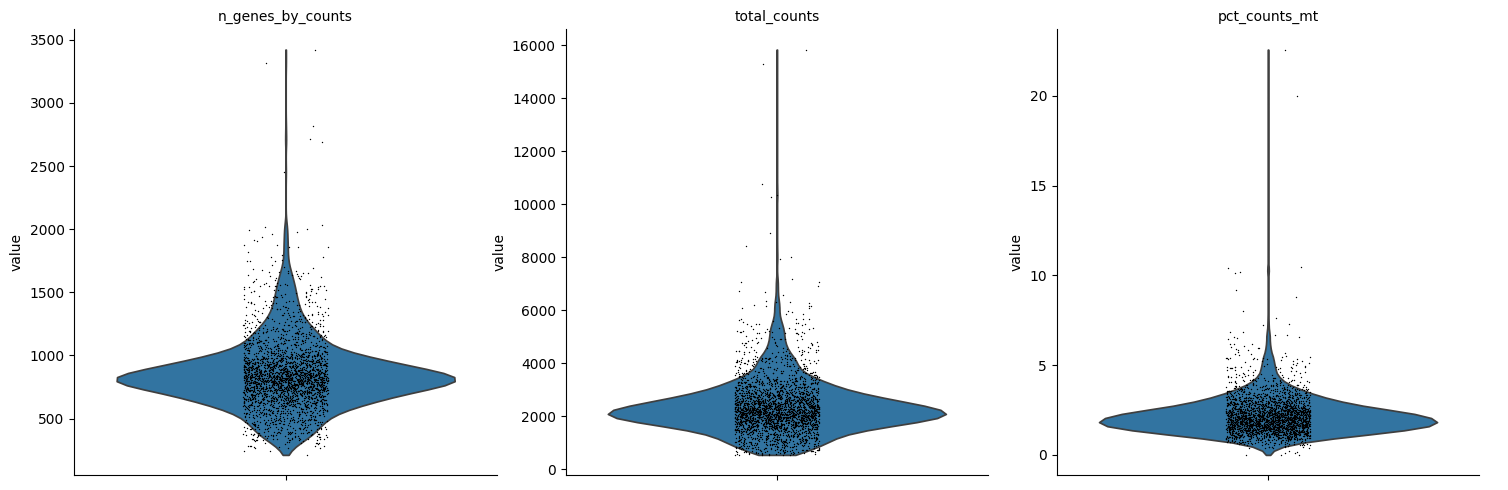

In [14]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [15]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [16]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [17]:
adata.layers["counts"] = adata.X.copy()

In [18]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

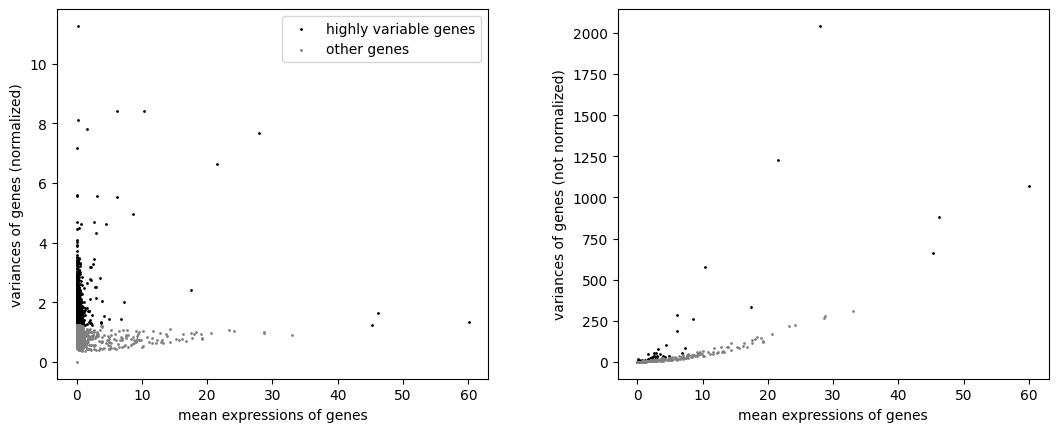

In [19]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

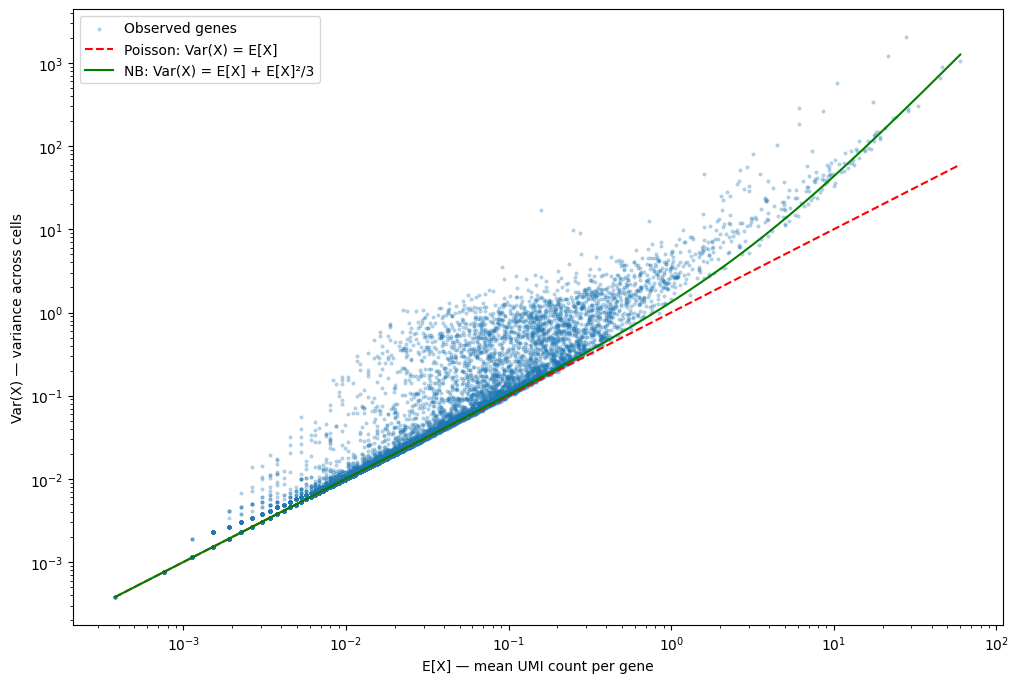

In [21]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [22]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [23]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

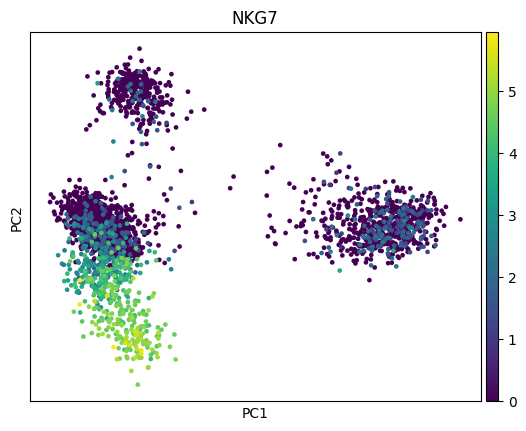

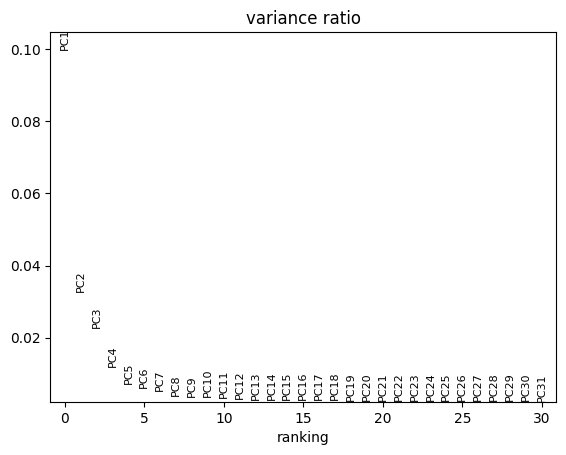

In [24]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [25]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили.

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [8]:
#перезагрузим данные
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

Можно посмотреть например по рибосомальным генам - ribo

In [9]:
adata.var['rib'] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var['hb'] = adata.var_names.str.match(r"^HB[ABDEGMQZ]\d*$")  #какой-нибудь гемоглобин - показатель контаминации эритроцитами

Построим Violin plot для всех метрик

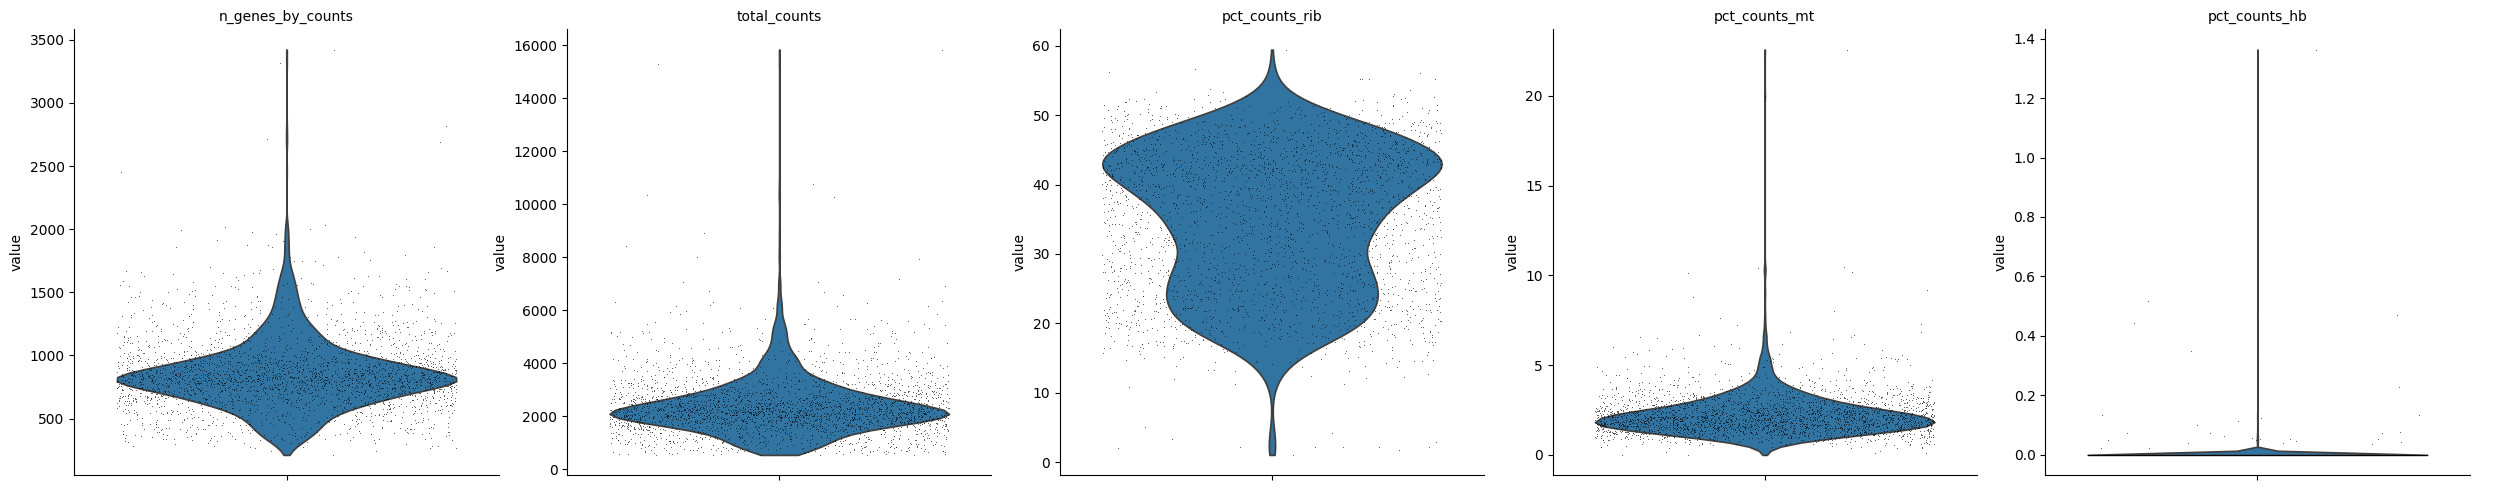

In [11]:
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["rib",'mt','hb'],
    percent_top=None,
    inplace=True,
)

QC_COLS = [
    "n_genes_by_counts",
    "total_counts",
    "pct_counts_rib",
    "pct_counts_mt",
    "pct_counts_hb"
]

sc.pl.violin(adata, QC_COLS, multi_panel=True, jitter=0.4, size=0.5)

Теперь построим гистограммы

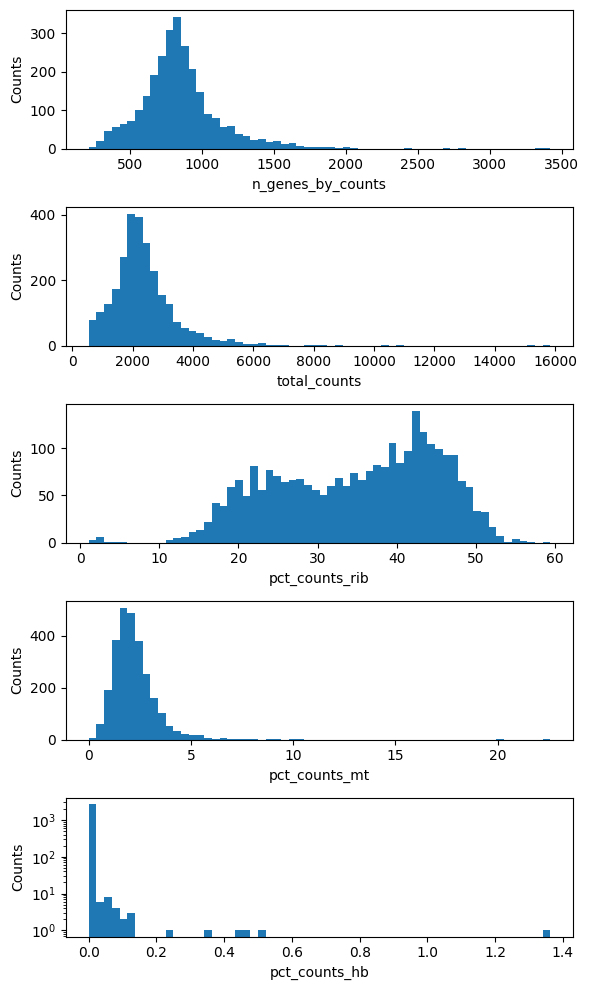

In [18]:
fig, axes = plt.subplots(5,1,figsize=(6,10))
for ax, col in zip(axes.flat, QC_COLS):
  ax.hist(adata.obs[col], bins=60)
  ax.set_xlabel(col)
  ax.set_ylabel('Counts')
  if '_hb' in col:
    ax.set_yscale('log')
plt.tight_layout()
plt.show()

График каунтов от количества клеток

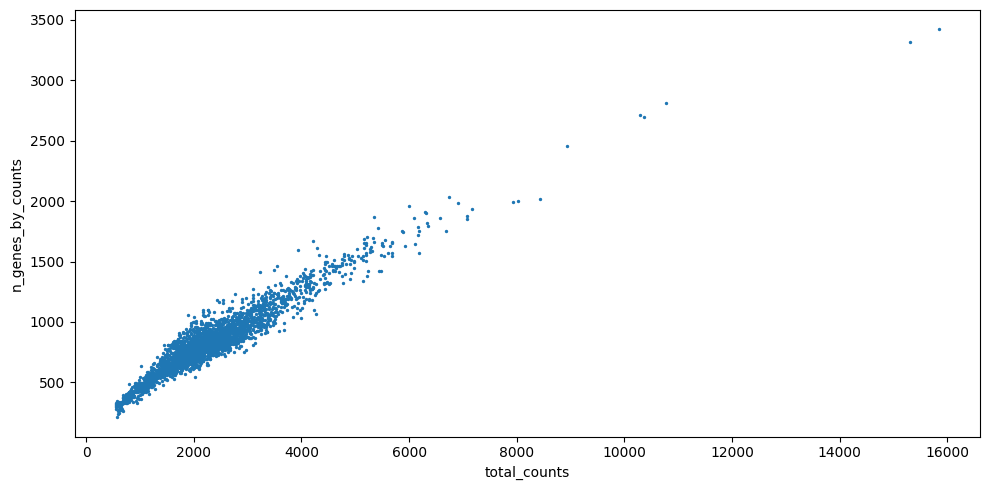

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
p = ax.scatter(
        adata.obs["total_counts"],
        adata.obs["n_genes_by_counts"],
        s = 2
    )
ax.set_xlabel("total_counts")
ax.set_ylabel("n_genes_by_counts")

plt.tight_layout()
plt.show()

* Подозрительны комбинации далеко уходящие от диагонали "число генов - число UMI", так как если мало генов, но очень много каунтов - дублеты, очень низкие значения - пустые капли например

По графикам подозрительными выглядят клетки
* С числом каунтов больше 5-6 тысяч (хотя они вроде лежат на прямой на графике, так что может быть это действительно клетки с очень высокой активностью)
* С числом генов меньше 500
* С большим уровнем митохондриальных каунтов - больше 5


* Метриками плохого качества могут быть низкое число геном и низкое число каунтов (как считали на занятии), высокая доля митохондриальных генов - погибающие клетки, гемоглобины - контаминация эритроцитами - плохая пробоподготовка. (+ еще клетки с очень низким уровнем рибосомальных генов - нет активного биосинтеза белка, могут быть мертвые клетки/пустые капли)

* В случае рибосомных генов, например, высокая доля не автоматически говорит, что клетка плохая, такие состояния физиологически возможны, например в активированных лимфоцитах

## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`.

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


Подготовительная часть

In [22]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata = adata[
    (adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)
].copy()
adata.layers["counts"] = adata.X.copy()

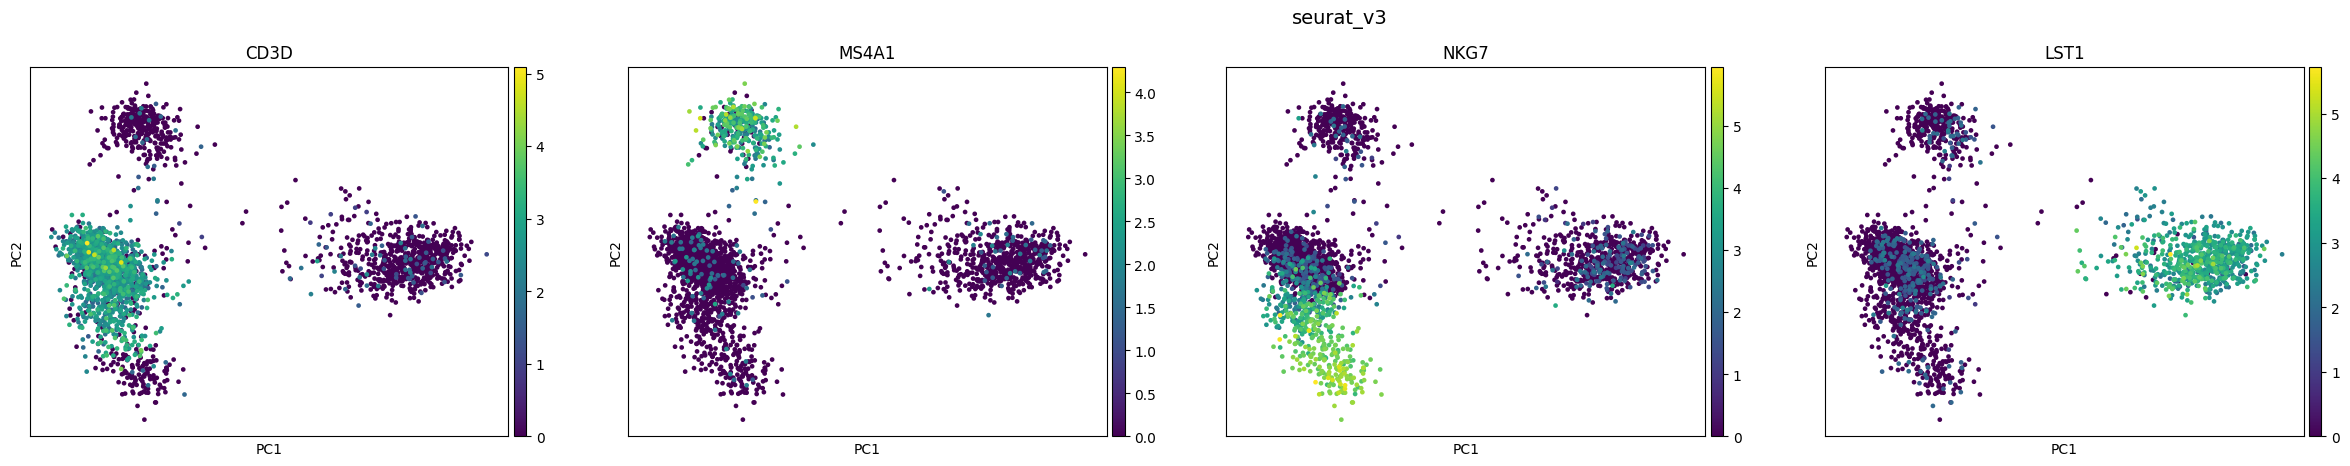

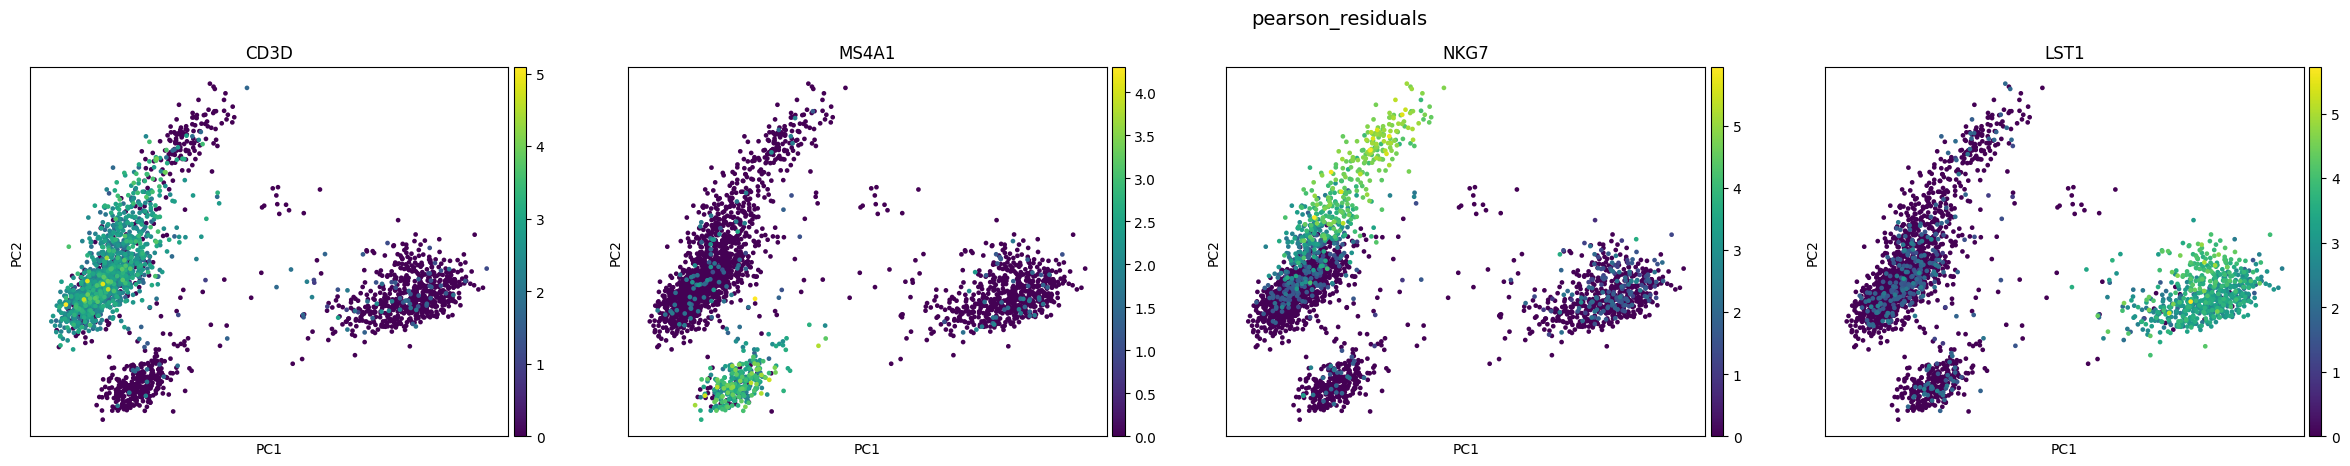

Общие гены в HVG: 1402


In [27]:
import scanpy as sc
import matplotlib.pyplot as plt

adata_base = adata.copy()
sc.pp.normalize_total(adata_base, target_sum=1e4)
sc.pp.log1p(adata_base)

adata_v3 = adata.copy()
adata_pr = adata.copy()


sc.pp.highly_variable_genes(adata_v3, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.experimental.pp.highly_variable_genes(
    adata_pr, flavor="pearson_residuals", n_top_genes=2000
)

adata_v3_for_pca = adata_base.copy()
adata_v3_for_pca.var["highly_variable"] = adata_v3.var["highly_variable"]
sc.tl.pca(adata_v3_for_pca, mask_var="highly_variable")
adata_pr_for_pca = adata_base.copy()
adata_pr_for_pca.var["highly_variable"] = adata_pr.var["highly_variable"]
sc.tl.pca(adata_pr_for_pca, mask_var="highly_variable")


markers = ["CD3D", "MS4A1", "NKG7", "LST1"]

fig1 = sc.pl.pca(adata_v3_for_pca, color=markers, ncols=4, return_fig=True)
fig2 = sc.pl.pca(adata_pr_for_pca, color=markers, ncols=4, return_fig=True)

fig1.suptitle('seurat_v3', fontsize=14, y=1.02)
fig2.suptitle('pearson_residuals', fontsize=14, y=1.02)

plt.show()

overlap = len(set(adata_v3.var_names[adata_v3.var["highly_variable"]]) &
              set(adata_pr.var_names[adata_pr.var["highly_variable"]]))
print('Общие гены в HVG:', overlap)

В результате несколько различется визуальный вид и морфология кластеров - в случае seurat_v3 они выглядят более округлыми. При этом характерные биологические маркеры остались распределены так же (сохранилась разбивка по кластерам).

Достаточно большое количество генов получилось общим для методов - 1402 (из 2000)

## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


In [34]:
adata_no_hwg = adata.copy()

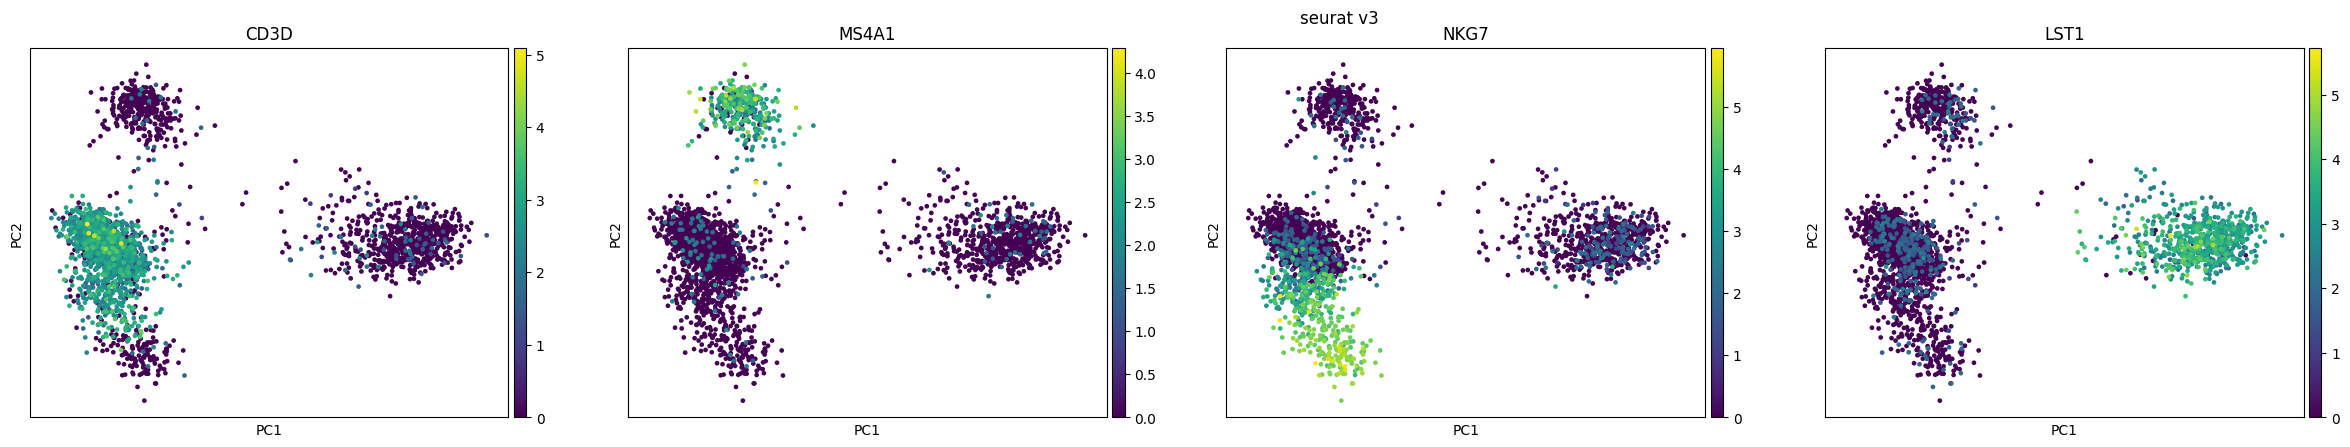

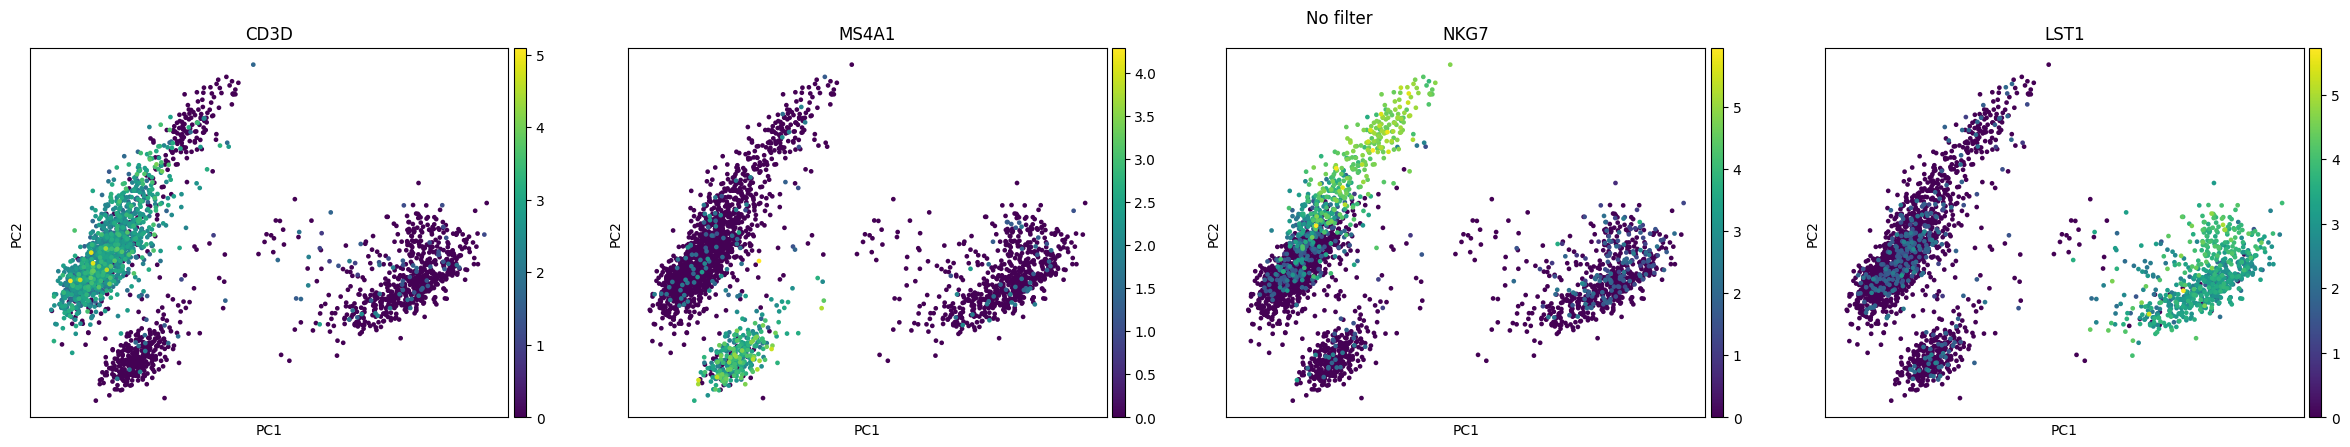

In [35]:
sc.pp.normalize_total(adata_no_hwg , target_sum=1e4)
sc.pp.log1p(adata_no_hwg)
sc.tl.pca(adata_no_hwg , n_comps=50)

fig1 = sc.pl.pca(adata_v3_for_pca, color=markers, ncols=4, return_fig=True)
fig2 = sc.pl.pca(adata_no_hwg , color=["CD3D", "MS4A1", "NKG7", "LST1"], ncols=4,return_fig=True)

fig1.suptitle('seurat v3')
fig2.suptitle('No filter')
fig1.show()
fig2.show()



Все кластеры стали диагональными, вытянутыми по направлению от начала координат. При этом в некоторых случаях разделение менее четкое.

Дополнительные гены - с низкой экспрессией, вносят много случайного шума (могут сильно отличаться в клетках одинакого типа) - в результате истинные различия искажаются, так как сл



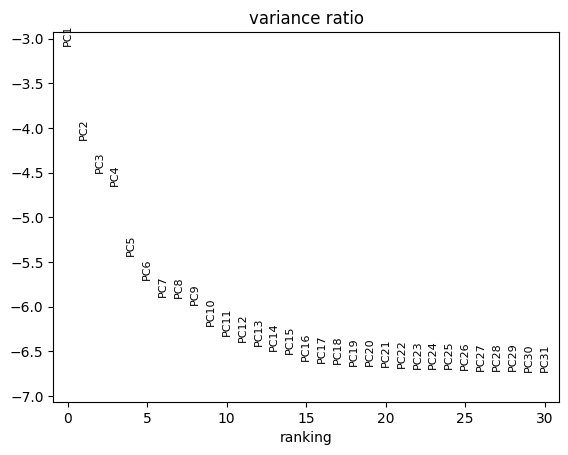

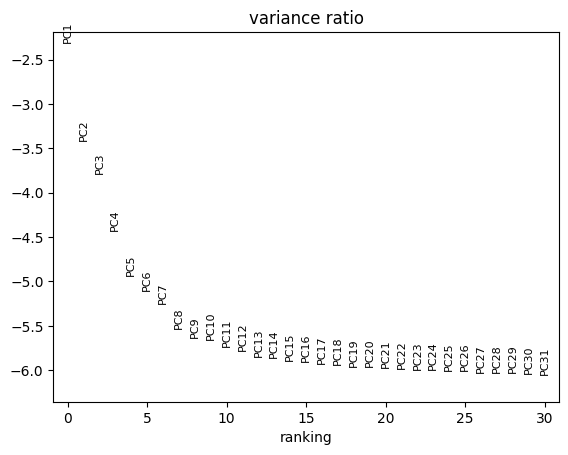

In [38]:
sc.pl.pca_variance_ratio(adata_no_hwg, log=True)
sc.pl.pca_variance_ratio(adata_v3_for_pca,log=True)

Видно, что с фильтрацией первые компоненты объясняют значительно больше дисперсии - первая компонента объясняет около e^-2.5 (там скорее -2.3) дисперсии с HVG и только e^-3 без. При этом график без HWG спадает гораздо плавнее.


Получается при использовании HVG первые компоненты объясняют большую долю дисперсии чем при использовании всех геном, так как мы срезаем фоновый шум от вариативности, которая не несет биологического смысла.

## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


Посчитаем средние UMI

In [40]:
adata_v3.layers["counts"]

<Compressed Sparse Column sparse matrix of dtype 'float32'
	with 2238732 stored elements and shape (2638, 13714)>

In [41]:
cnt = adata_v3.layers["counts"]
mean_umi = np.asarray(cnt.mean(axis=0)).ravel()
adata_v3.var["mean_umi"] = mean_umi

In [42]:
is_hvg = adata_v3.var["highly_variable"].values #HVG

In [43]:
top_hvg     = adata_v3.var.loc[is_hvg].nlargest(50, "mean_umi")
top_non_hvg = adata_v3.var.loc[~is_hvg].nlargest(50, "mean_umi")

In [44]:
print("=== Топ-50 HVG по среднему UMI ===")
print(top_hvg[["mean_umi"]].head(50))
print("\n=== Топ-50 НЕ-HVG по среднему UMI ===")
print(top_non_hvg[["mean_umi"]].head(50))


=== Топ-50 HVG по среднему UMI ===
           mean_umi
MALAT1    60.036732
TMSB4X    46.140289
B2M       45.289223
FTL       27.999430
FTH1      21.535463
ACTB      17.458569
LYZ       10.408192
CD74       8.579643
S100A4     7.343126
MT-CO2     6.888643
HLA-DRA    6.151281
S100A9     6.146330
OAZ1       4.925751
CST3       4.471583
S100A6     4.231647
LTB        3.965538
SH3BGRL3   3.776385
VIM        3.765769
TYROBP     3.527301
S100A8     3.174760
LGALS1     3.012143
COTL1      3.010634
HLA-DPB1   2.926478
SAT1       2.788114
NKG7       2.637610
HLA-DPA1   2.616391
HLA-DRB1   2.551569
CD37       2.310109
IFITM2     2.302523
AIF1       2.288484
ARPC1B     2.264994
LST1       2.205845
IL32       2.108428
UBB        2.093276
FCER1G     2.071272
CTSS       2.061041
CCL5       2.019716
S100A11    1.969684
SRGN       1.912825
S100A10    1.882122
PSAP       1.734278
GNLY       1.599320
KLF6       1.595163
ANXA1      1.588337
FCN1       1.579610
RBM3       1.368095
GSTP1      1.339279
GPX1 

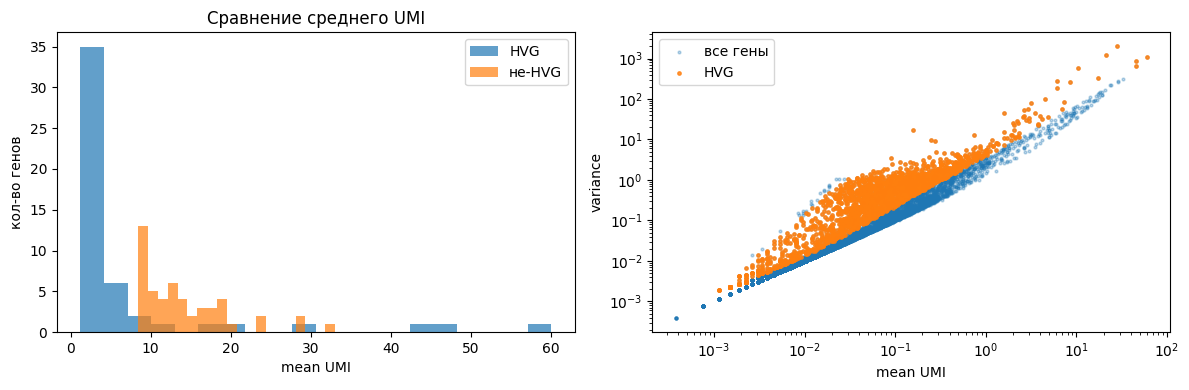

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(top_hvg["mean_umi"],   bins=20, alpha=0.7, label="HVG")
axes[0].hist(top_non_hvg["mean_umi"], bins=20, alpha=0.7, label="не-HVG")
axes[0].set_xlabel("mean UMI"); axes[0].set_ylabel("кол-во генов"); axes[0].legend()
axes[0].set_title("Сравнение среднего UMI")

axes[1].scatter(adata_v3.var["mean_umi"], adata_v3.var["variances"],
                s=4, alpha=0.3, label="все гены")
axes[1].scatter(adata_v3.var.loc[is_hvg, "mean_umi"],
                adata_v3.var.loc[is_hvg, "variances"],
                s=6, alpha=0.8, label="HVG")
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("mean UMI"); axes[1].set_ylabel("variance")
axes[1].legend()
plt.tight_layout()
plt.show()

HVG - не обязательно самые экспрессируемые гены, это гены с избыточной вариативностью которые отклоняются от пуассоновского распределения (получается NegBin)  - как можно заметить по гистограмме, есть HVG и с UMI меньше чем у не-HVG, как и наоборот.

Самыми экспрессируемыми среди не HVG оказались в основном различные рибосомальные гены - везде достаточно хорошо экспрессируются.

Среди HVG -

MALAT1    60.036732 - длинная некодирующая РНК
TMSB4X    46.140289 - регулятор актина
B2M       45.289223 - компонент МНС-I (b2-микроглобулин
FTL       27.999430 - легкая цепь ферритина
FTH1      21.535463 - тяжелая цепь ферритина
ACTB      17.458569 - бета-актин


Ген может иметь очень высокую экспрессию (RPL10   33.017464 - mean UMI больше чем у большинства HVG) - но если его дисперсия будет соответствовать среднему - укладываться в модель, то он не станет HVG

## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

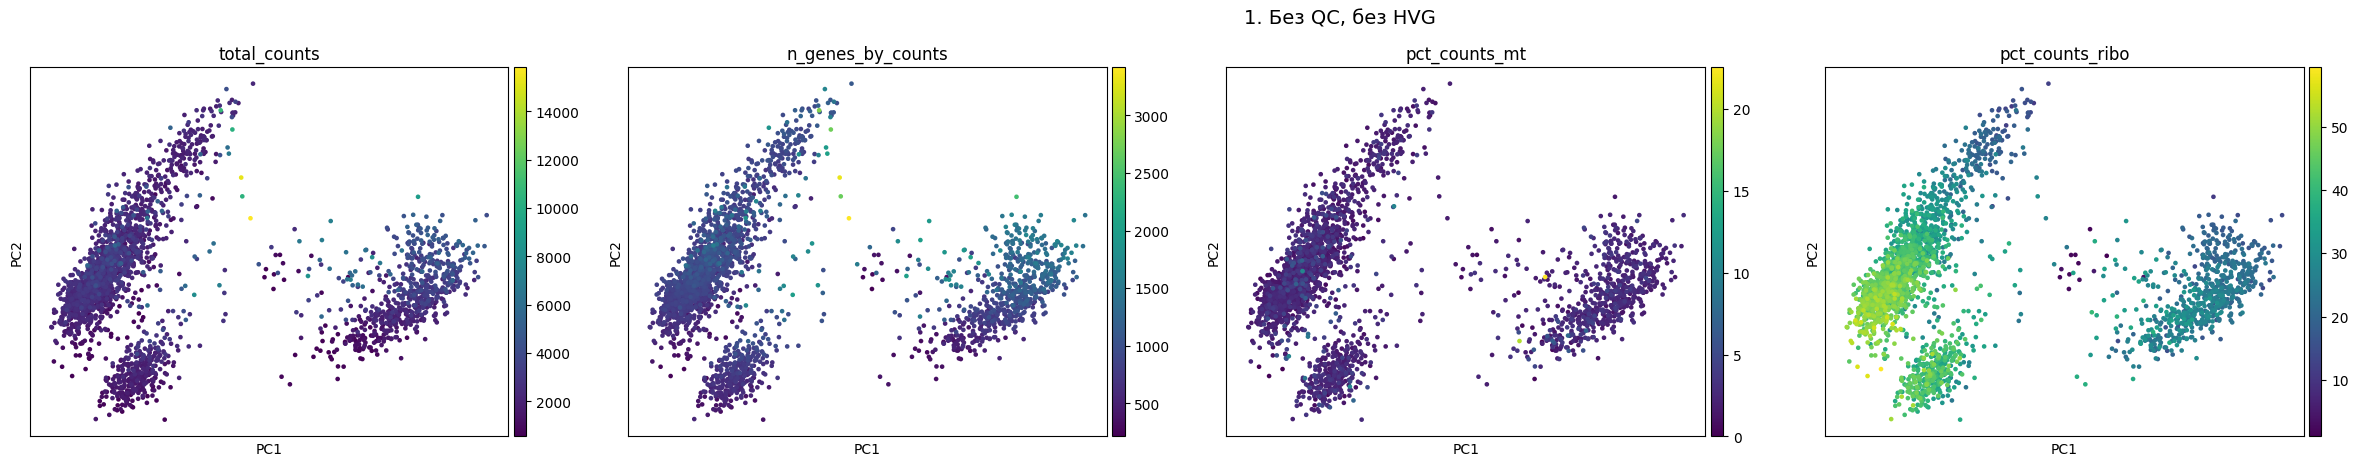

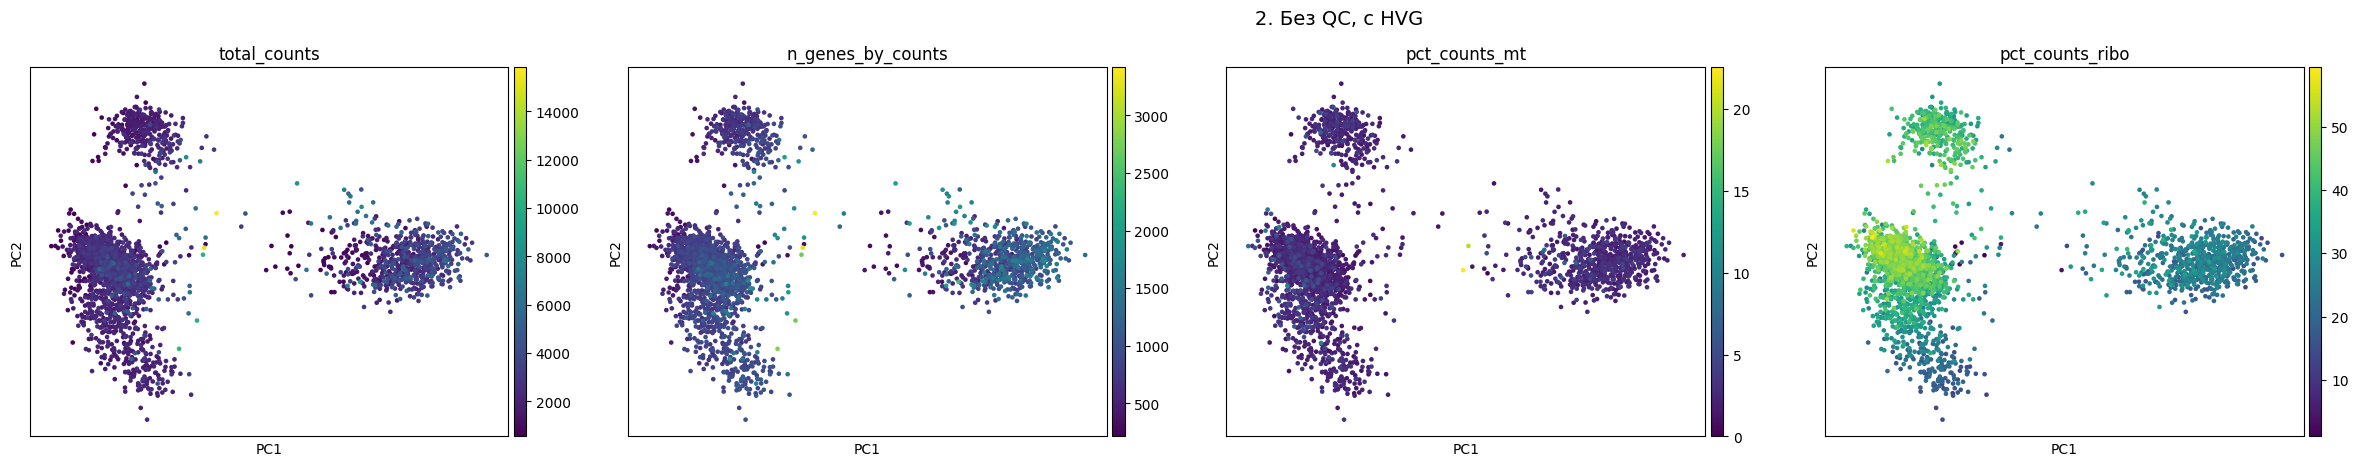

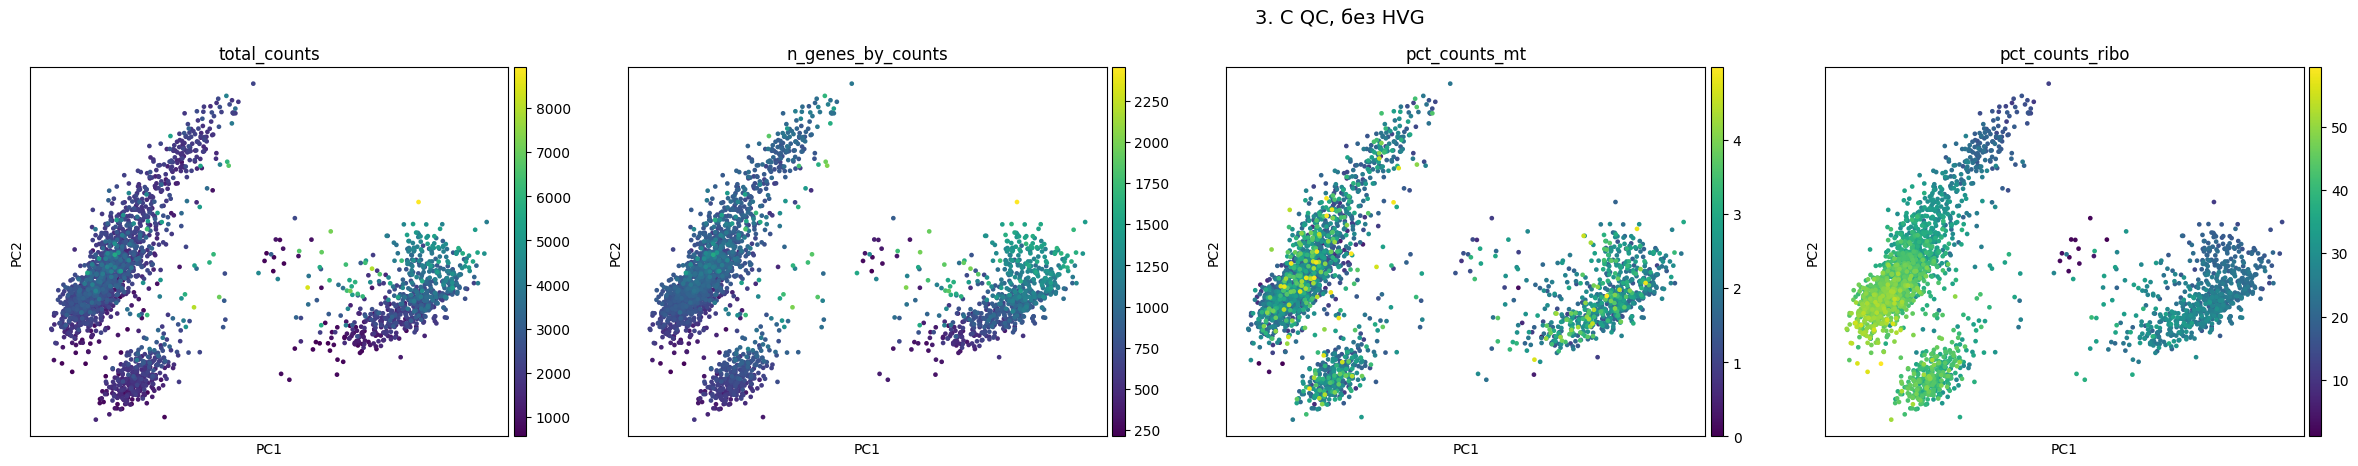

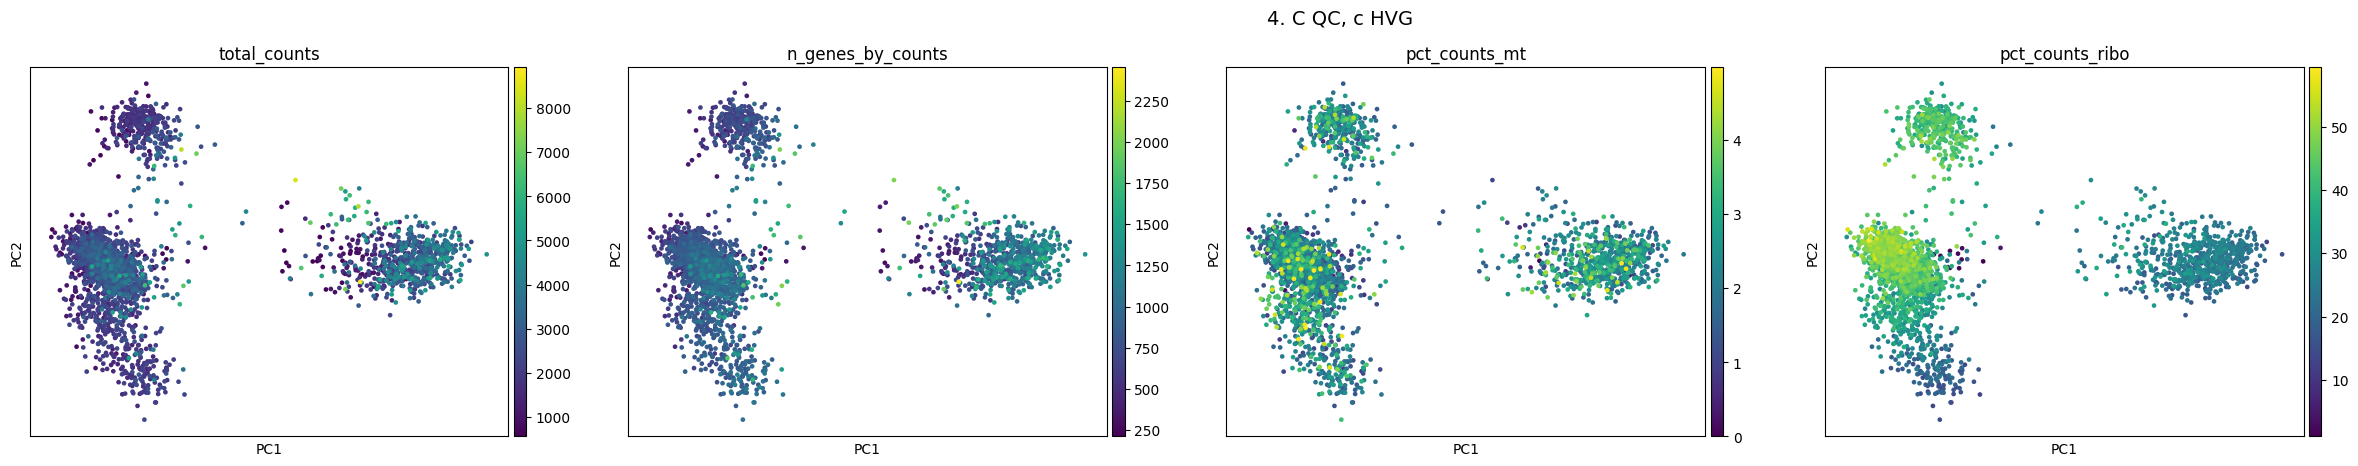

In [46]:
def build_pca(qc_filter=False, use_hvg=False, n_top=2000):
    a = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
    a.var["mt"]   = a.var_names.str.startswith("MT-")
    a.var["ribo"] = a.var_names.str.startswith(("RPS", "RPL"))
    sc.pp.calculate_qc_metrics(a, qc_vars=["mt", "ribo"], percent_top=None, inplace=True)
    if qc_filter:
        sc.pp.filter_cells(a, min_genes=200)
        sc.pp.filter_genes(a, min_cells=3)
        a = a[(a.obs.n_genes_by_counts < 2500) & (a.obs.pct_counts_mt < 5)].copy()
    a.layers["counts"] = a.X.copy()
    if use_hvg:
        sc.pp.highly_variable_genes(a, layer="counts", flavor="seurat_v3", n_top_genes=n_top)

    sc.pp.normalize_total(a, target_sum=1e4)
    sc.pp.log1p(a)

    if use_hvg:
        sc.tl.pca(a, mask_var="highly_variable")
    else:
        sc.tl.pca(a)

    return a

cases = {
      '1. Без QC, без HVG': build_pca(qc_filter=False, use_hvg=False),
      '2. Без QC, c HVG': build_pca(qc_filter=False, use_hvg=True),
      '3. C QC, без HVG': build_pca(qc_filter=True, use_hvg=False),
      '4. C QC, c HVG': build_pca(qc_filter=True, use_hvg=True)
  }

for name, a in cases.items():
  fig = sc.pl.pca(
        a,
        color=["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"],
        ncols=4,
        return_fig=True
    )
  fig.suptitle(name, fontsize=14, y=1.02)
  plt.show()

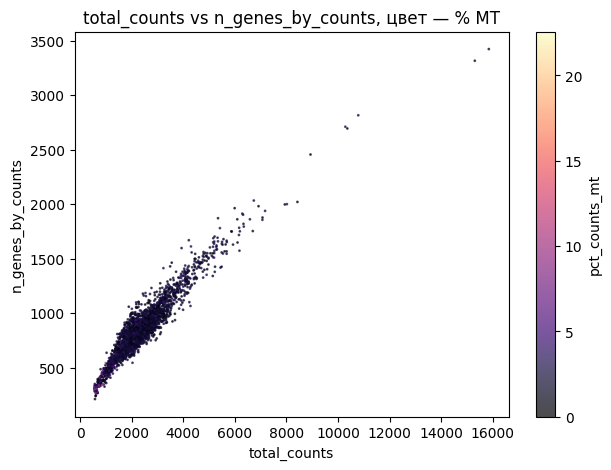

In [65]:
a_raw = cases['1. Без QC, без HVG']
fig, ax = plt.subplots(figsize=(7, 5))
p = ax.scatter(a_raw.obs["total_counts"], a_raw.obs["n_genes_by_counts"],
               c=a_raw.obs["pct_counts_mt"], s=1,alpha=0.7, cmap="magma")
ax.set_xlabel("total_counts"); ax.set_ylabel("n_genes_by_counts")
plt.colorbar(p, label="pct_counts_mt")
plt.title("total_counts vs n_genes_by_counts, цвет — % MT")
plt.show()

Без HVG мы получаем кластеры, ориентированные по диагонали - много необъясненной первыми двумя компонентами дисперсии

Сложно сказать, связано ли положение клеток с количество м tota

Можно заметить, что клетки с высокой долей митохондрий образуют отдельные островки и при отсутствии HVG клетки укладываются в градиент от точки начала координат (возможно одна из главных компонент объясняет фактически степень повреждения клеток)



## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [51]:
adata_v3

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean_umi'
    uns: 'hvg'
    layers: None (.X), 'counts'


=== PC1: топ-10 положительных loadings ===
LYZ       0.220199
CST3      0.212370
S100A9    0.210871
TYROBP    0.199072
S100A8    0.170560
LGALS1    0.168186
AIF1      0.166196
LST1      0.165629
FCER1G    0.156248
FCN1      0.150878
Name: PC1, dtype: float64
=== PC1: топ-10 отрицательных loadings ===
LTB      -0.112827
IL32     -0.106144
MALAT1   -0.067260
IL7R     -0.059417
CCL5     -0.051053
CD2      -0.045544
CTSW     -0.043735
STK17A   -0.037906
ACAP1    -0.036313
CD247    -0.036139
Name: PC1, dtype: float64

=== PC2: топ-10 положительных loadings ===
HLA-DRA     0.267638
CD74        0.209744
HLA-DPB1    0.197693
HLA-DRB1    0.192726
CD79A       0.183641
HLA-DPA1    0.180487
HLA-DQA1    0.169166
HLA-DQB1    0.160824
CD79B       0.157985
HLA-DRB5    0.142120
Name: PC2, dtype: float64
=== PC2: топ-10 отрицательных loadings ===
NKG7     -0.216003
S100A4   -0.180782
CCL5     -0.165345
IL32     -0.144603
GNLY     -0.134453
CTSW     -0.134233
GZMA     -0.134096
CST7     -0.131238
SRGN  

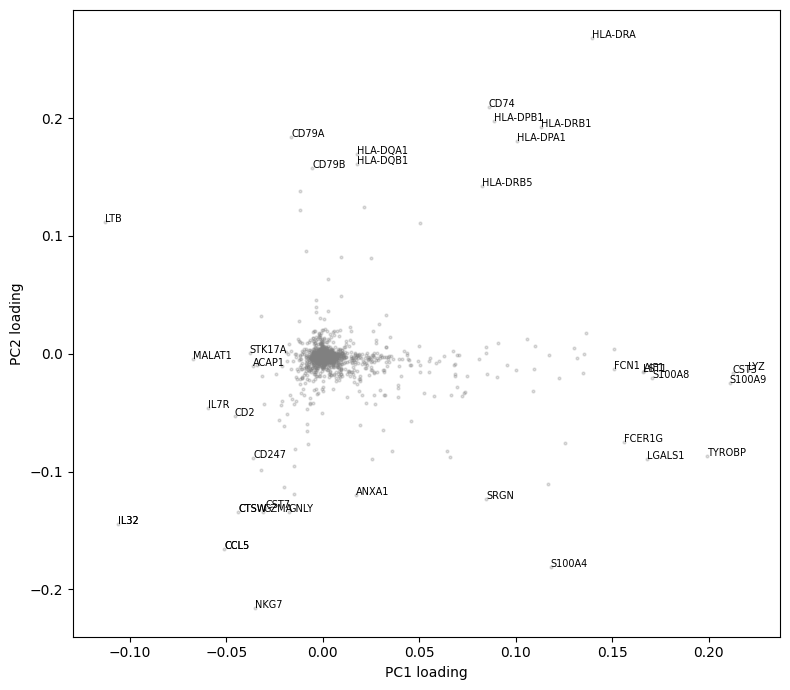

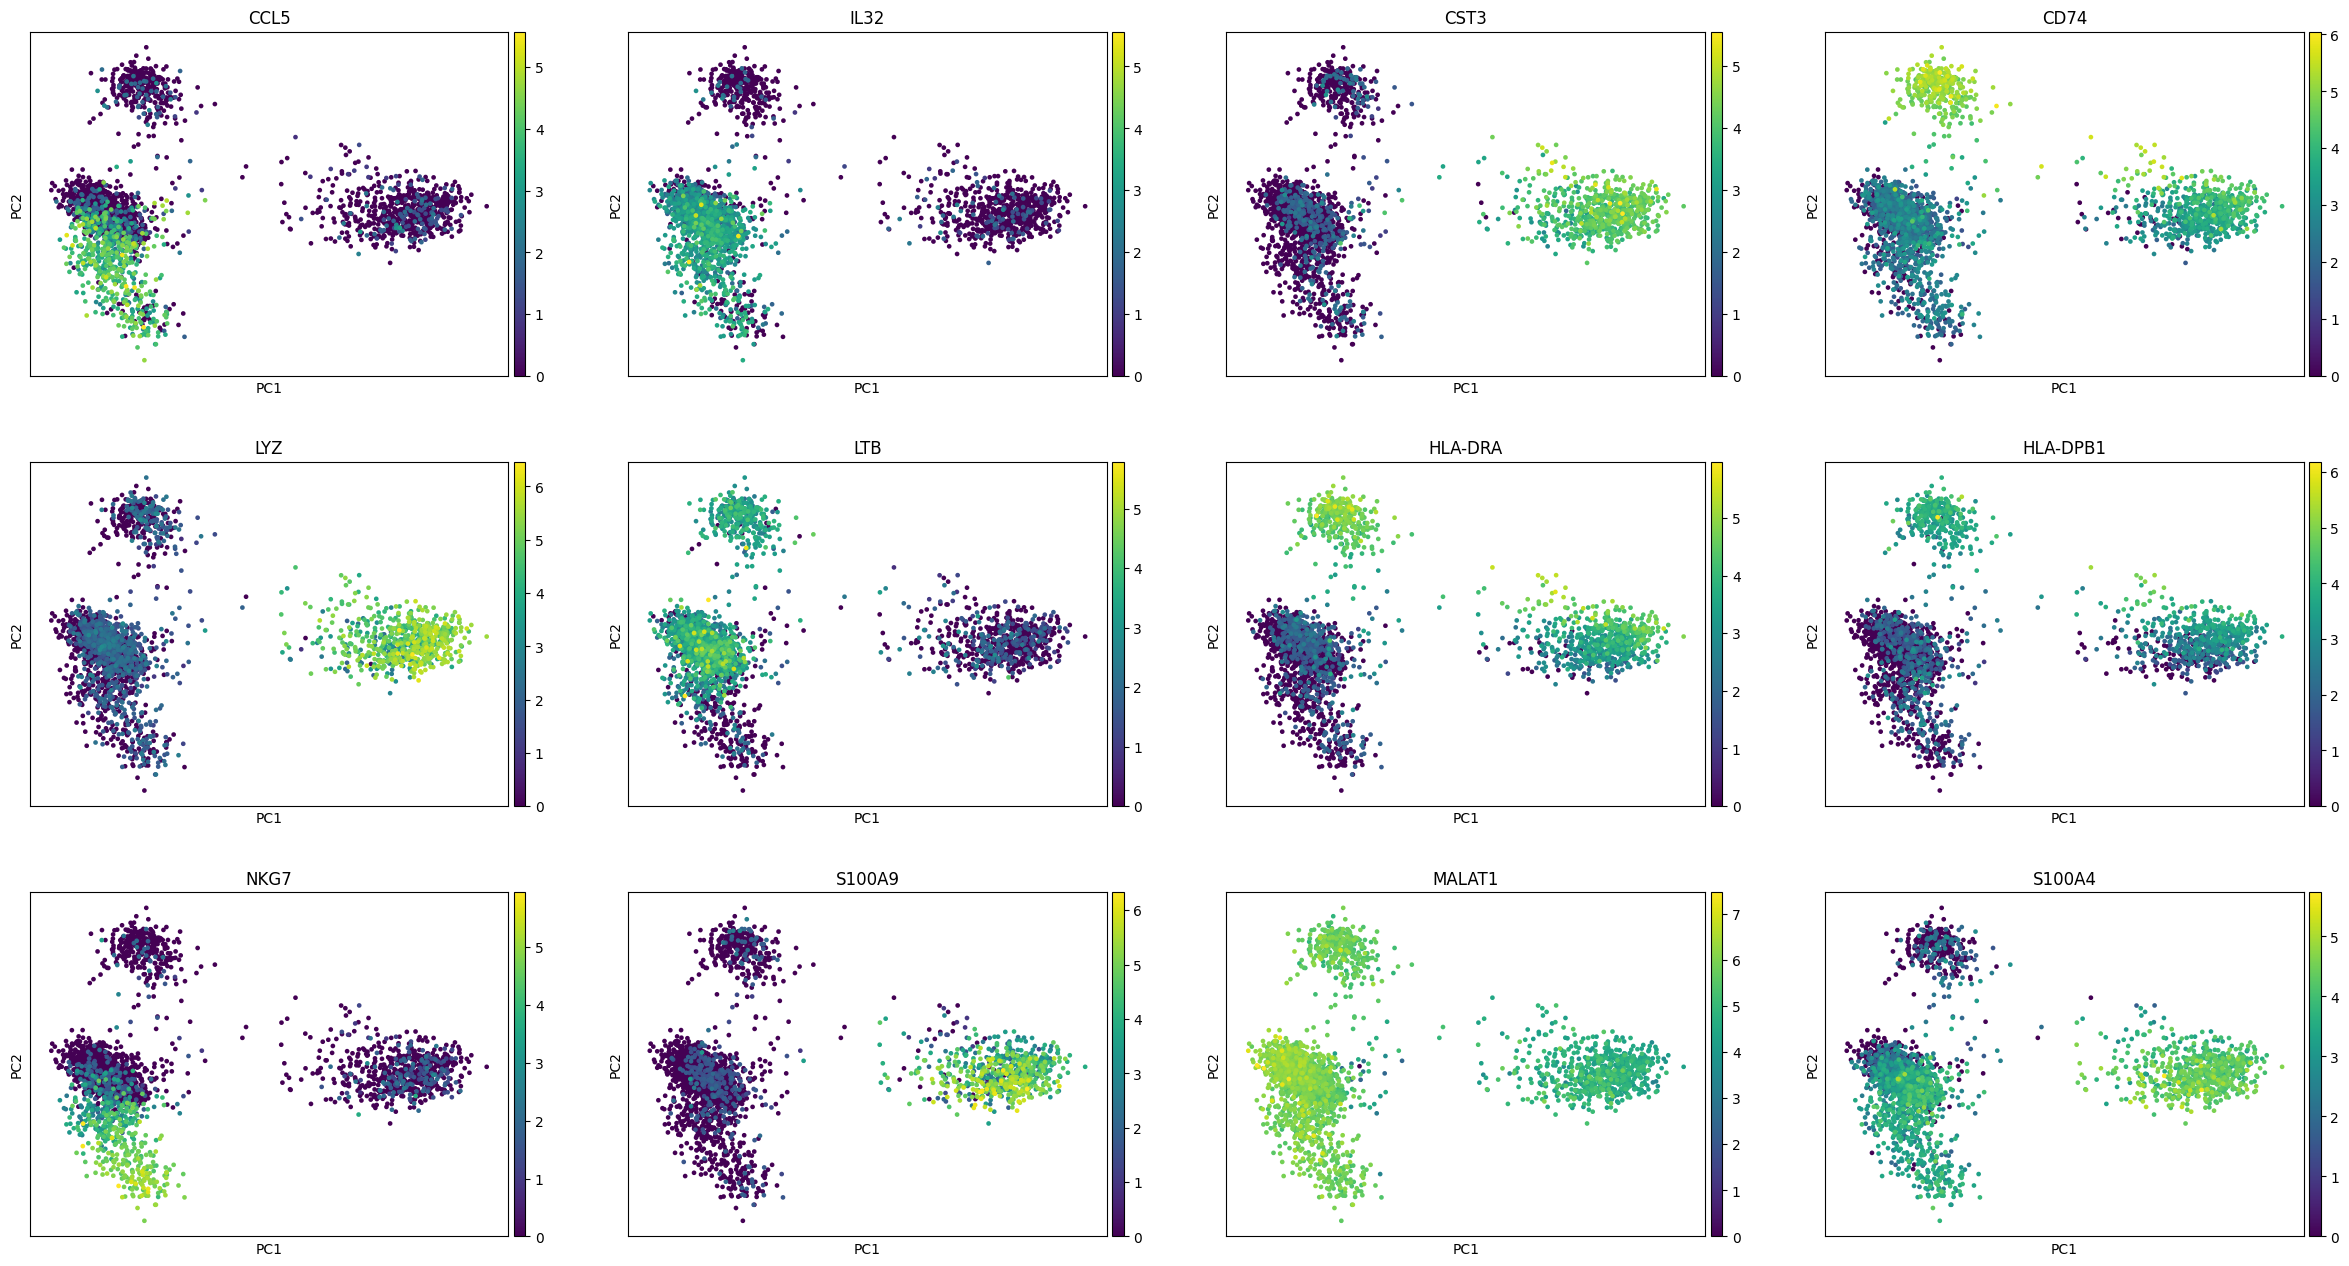

In [53]:
loadings = pd.DataFrame(
    adata_v3_for_pca.varm["PCs"][:, :2],
    index=adata_v3_for_pca.var_names,
    columns=["PC1", "PC2"],
)

def top_and_bottom(series, n=10):
    return series.nlargest(n), series.nsmallest(n)

for pc in ["PC1", "PC2"]:
    pos, neg = top_and_bottom(loadings[pc], n=10)
    print(f"\n=== {pc}: топ-10 положительных loadings ===")
    print(pos)
    print(f"=== {pc}: топ-10 отрицательных loadings ===")
    print(neg)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(loadings["PC1"], loadings["PC2"], s=4, alpha=0.25, color="gray")
for pc in ["PC1", "PC2"]:
    pos, neg = top_and_bottom(loadings[pc], n=10)
    for g in list(pos.index) + list(neg.index):
        ax.annotate(g, (loadings.loc[g, "PC1"], loadings.loc[g, "PC2"]),
                    fontsize=7)
ax.set_xlabel("PC1 loading"); ax.set_ylabel("PC2 loading")

plt.tight_layout()
plt.show()

interesting = list(set(
    loadings["PC1"].nlargest(3).index.tolist()
    + loadings["PC1"].nsmallest(3).index.tolist()
    + loadings["PC2"].nlargest(3).index.tolist()
    + loadings["PC2"].nsmallest(3).index.tolist()
))
sc.pl.pca(adata_v3_for_pca, color=interesting, ncols=4)

PC1 сильнее всего определяется генами моноцитов (LYZ. CST3, S100A8/9) с положительным знаком и с генами Т-клеток (LTB, IL32, IL7R, CD247, CD2) с отрицательным знаком.

PC2 определяется генами B-клеток и MHC-II комплекса (HLA-DRA, CD74, CD79A/B, HLA-DPB1) с положительным знаком и цитотоксическими генами NK-клеток (NKG7, GNLY, GZMA, CCL5) с отрицательным знаком.

Получатся что обе компоненты напрямую связаны с различными иммунными клеточными популяциями. С клеточными циклом и QC практически не связаны, так как в топах нет соответствующих маркеров, рибосомальных и митохондриальных генов. - В целом можно интерпретировать оси PC как
* PC1: миелоидные клетки - лимфоидные клетки
* PC2: антиген-презентирующие клетки - цитотоксические клетки

Это подтверждатеся распределением уровней экспрессии на карте PCA - например кластер справа похож на моноциты - высокий уровень LYZ/CST3/S100A8

## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток.

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

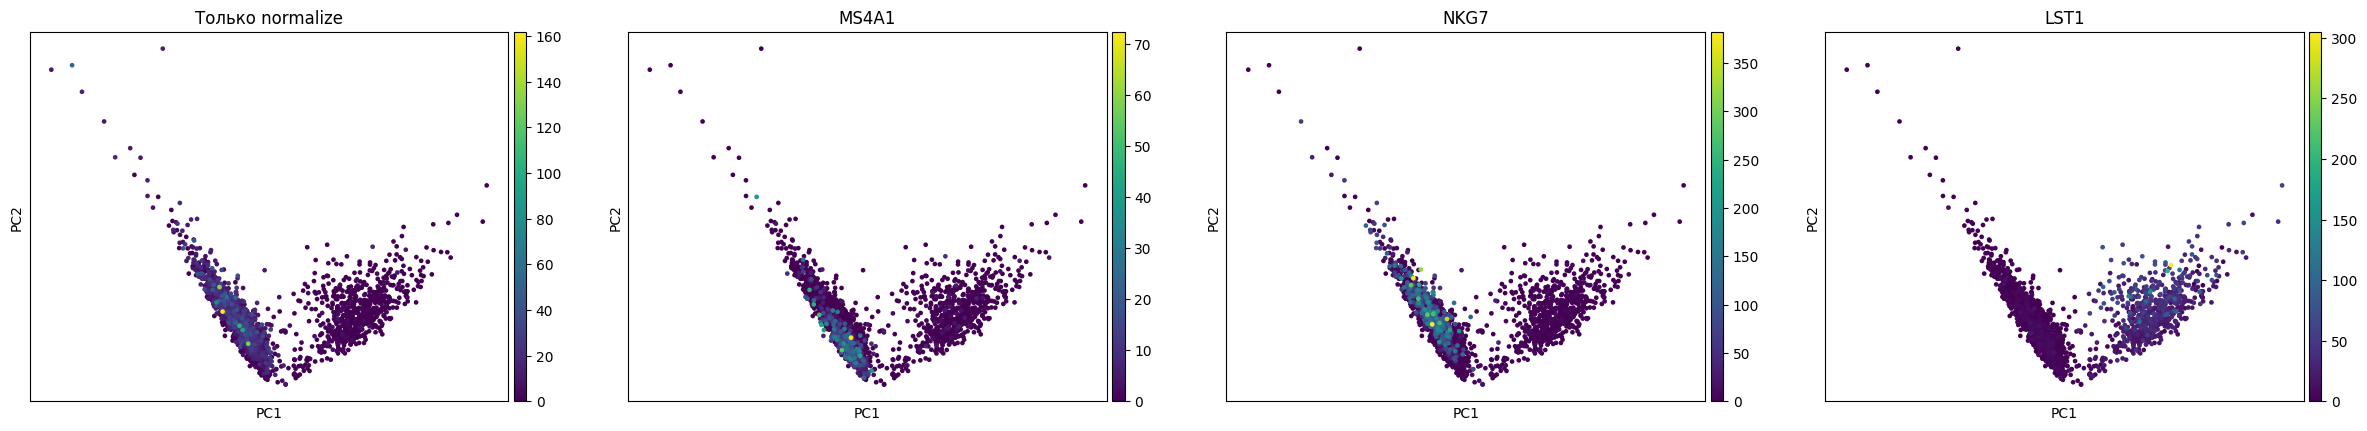

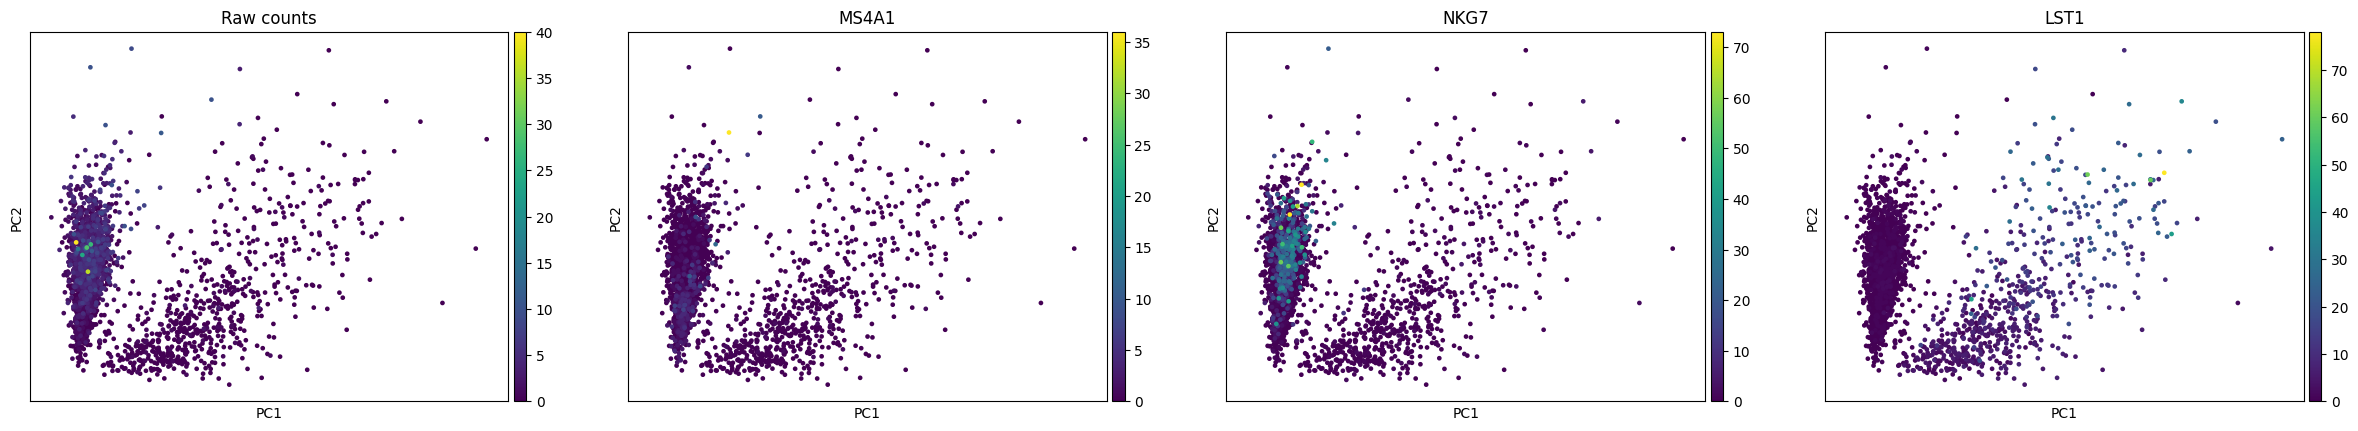

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


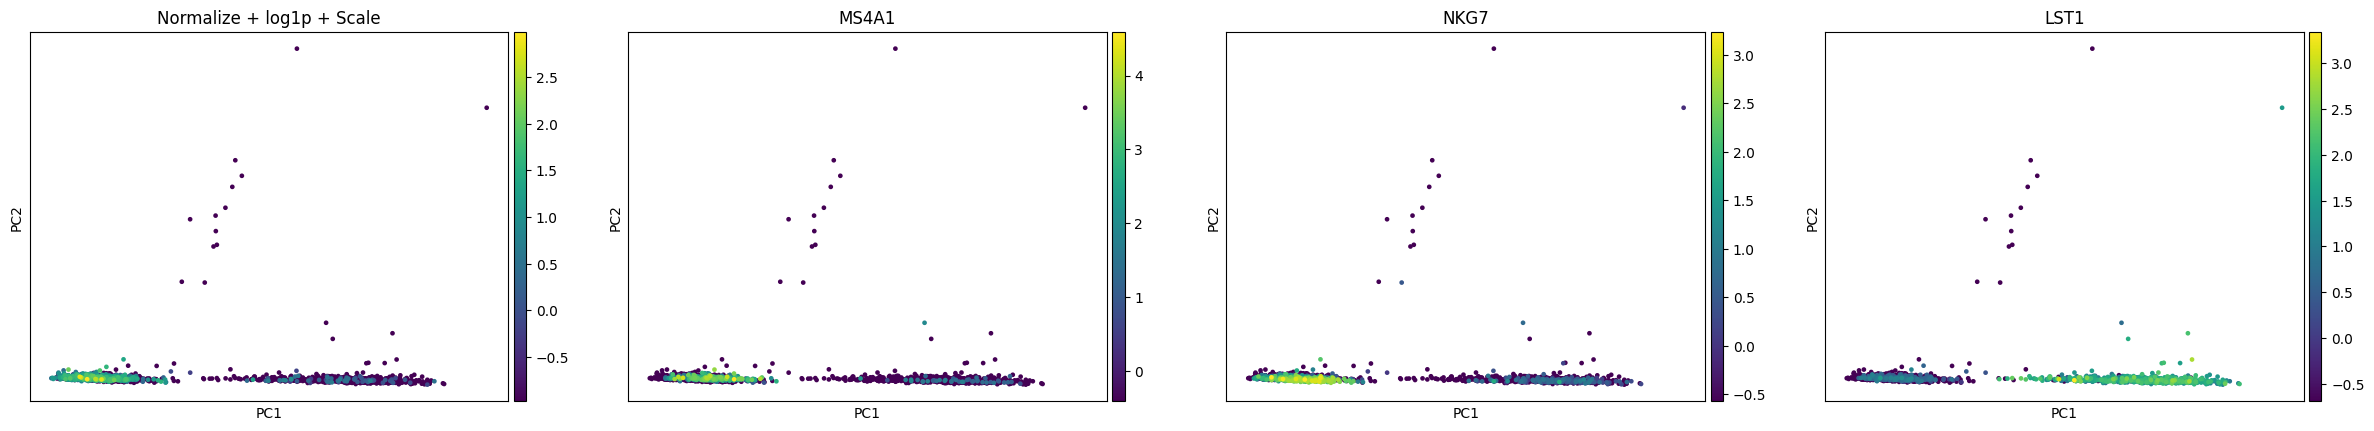

In [60]:
import scanpy as sc
import matplotlib.pyplot as plt

markers = ["CD3D", "MS4A1", "NKG7", "LST1"]


a_nolog = adata.copy()
sc.pp.highly_variable_genes(a_nolog, flavor="seurat_v3", n_top_genes=2000, layer="counts")

sc.pp.normalize_total(a_nolog, target_sum=1e4)
sc.tl.pca(a_nolog, mask_var="highly_variable")
sc.pl.pca(a_nolog, color=markers, ncols=4, title="Только normalize")


a_raw = adata.copy()
sc.pp.highly_variable_genes(a_raw, flavor="seurat_v3", n_top_genes=2000, layer="counts")

sc.tl.pca(a_raw, mask_var="highly_variable")
sc.pl.pca(a_raw, color=markers, ncols=4, title="Raw counts")


a_scaled = adata.copy()
sc.pp.highly_variable_genes(a_scaled, flavor="seurat_v3", n_top_genes=2000, layer="counts")

sc.pp.normalize_total(a_scaled, target_sum=1e4)
sc.pp.log1p(a_scaled)
sc.pp.scale(a_scaled)
sc.tl.pca(a_scaled, mask_var="highly_variable")
sc.pl.pca(a_scaled, color=markers, ncols=4, title="Normalize + log1p + Scale")

1) График получился V-образный. Цвет распределен очень неравномерно и при этом сложно выделить какие-либо кластеры. Без логарифмирования дисперсия некоторых генов получается огромной - это захватывается первыми компонентами.

2) Один вертикальный кластер и один размытый -  в целом точки достаточно хаотичны. Фактически просто смотрим размер клетки в total counts потому что не нормализирует прочтения ридов.

3) В целом есть кластеры, но из-за масштабирования все точки сжались вместе кроме нескольких выбросов. Концентуально scale делает для всех геном одинаковую дисперсию, для того чтобы анализировать все гены например.


Получается в случае нормализации мы убираем техническую разницу в глубине, логарифмированием сжимаем динамический диапазон, чтобы оверэкспрессируемые гены не мешали, scale в данном случае навредил, так как уже отобрали HVG, но он потенциально может быть полезен если хотим ловить редкие гены или смотреть сразу все.

## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?